In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
import shap


In [3]:
# 1. DATA PREPARATION
# ==========================================
print("--- 1. Loading & Preparing Dataset ---")
df = pd.read_csv("mental-state.csv")

# We know the target column is 'Label' and values are 0.0, 1.0, 2.0
target_col = "Label"

# Create a binary target: Class 2.0 (Target State) vs Others (0.0 and 1.0)
y = np.where(df[target_col] == 2.0, 1, 0)
X = df.drop(columns=[target_col]).values
feature_names = df.drop(columns=[target_col]).columns.tolist()

print(f"Feature matrix shape: {X.shape}")
print(f"Class distribution (1=Target State, 0=Background): {np.bincount(y)}")

# Create a copy of the dataset for visualization
df_eda = pd.DataFrame(X, columns=feature_names)
df_eda['binary_target'] = y


--- 1. Loading & Preparing Dataset ---
Feature matrix shape: (2479, 988)
Class distribution (1=Target State, 0=Background): [1649  830]



--- 2. Exploratory Data Analysis ---
Missing Values in dataset: 0


/var/folders/vn/s751ngvx7zn63_xcfg5wdb5w0000gn/T/ipykernel_97008/2100262421.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='binary_target', data=df_eda, palette='viridis')


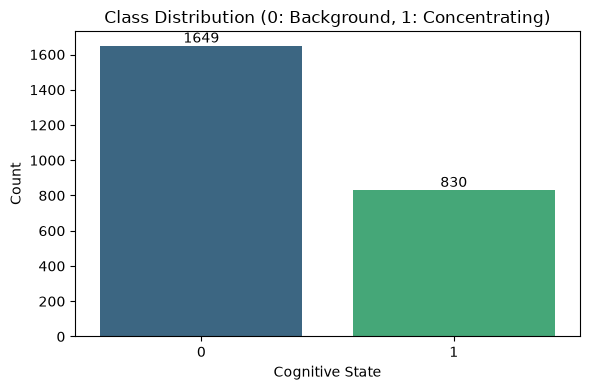

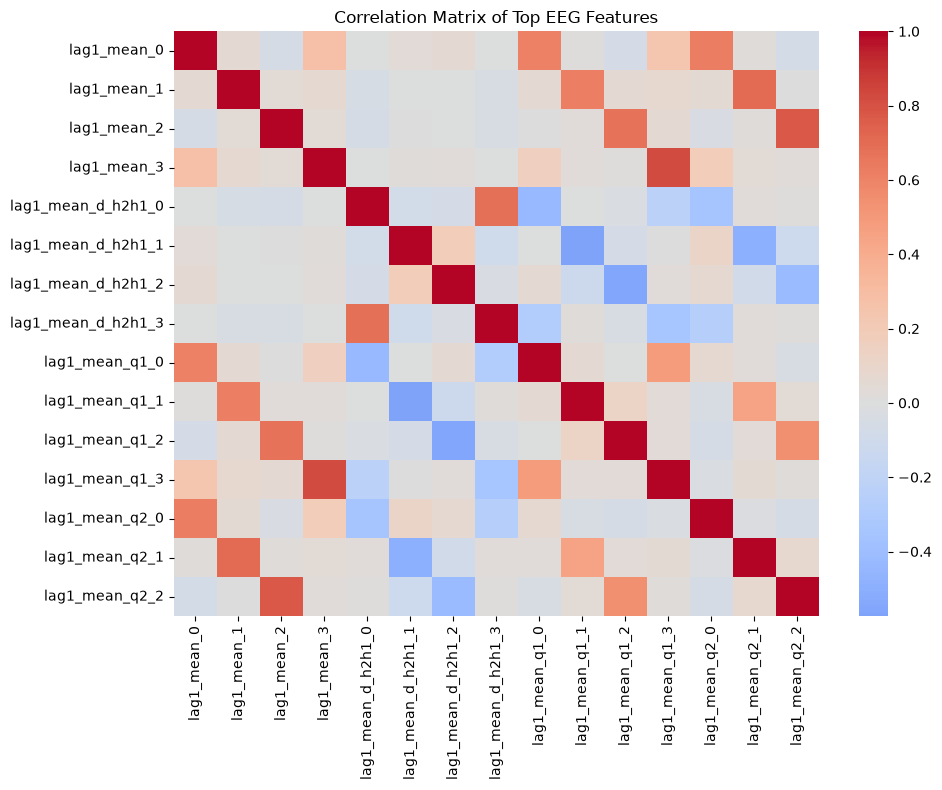

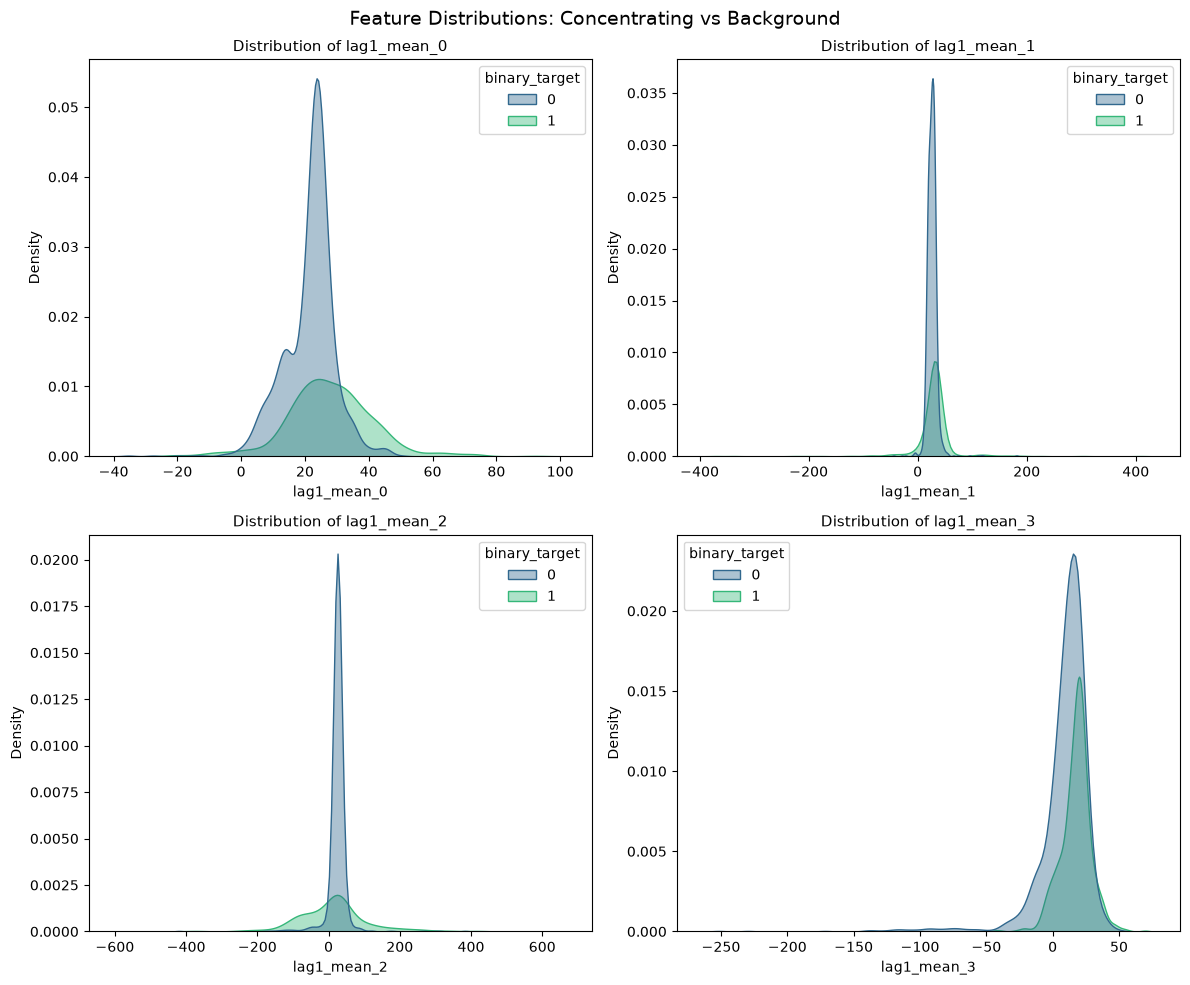

In [4]:
# ==========================================
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
print("\n--- 2. Exploratory Data Analysis ---")
print(f"Missing Values in dataset: {df_eda.isnull().sum().sum()}")

# Plot A: Class Balance
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='binary_target', data=df_eda, palette='viridis')
plt.title("Class Distribution (0: Background, 1: Concentrating)", fontsize=12)
plt.xlabel("Cognitive State")
plt.ylabel("Count")

# Add count annotations on top of the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig("eda_class_balance.png", dpi=300)
plt.show()

# Plot B: Correlation Matrix (Top 15 features for readability)
plt.figure(figsize=(10, 8))
cols_to_plot = feature_names[:15] if len(feature_names) > 15 else feature_names
corr_matrix = df_eda[cols_to_plot].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title("Correlation Matrix of Top EEG Features", fontsize=12)
plt.tight_layout()
plt.savefig("eda_correlation.png", dpi=300)
plt.show()

# Plot C: Feature Distributions by Class
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot[:4]):
    sns.kdeplot(data=df_eda, x=col, hue='binary_target', fill=True, alpha=0.4, palette='viridis', ax=axes[i])
    axes[i].set_title(f"Distribution of {col}", fontsize=11)
    
plt.suptitle("Feature Distributions: Concentrating vs Background", fontsize=14)
plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=300)
plt.show()



In [5]:
# ==========================================
# 3. CROSS-VALIDATION & MODEL TRAINING
# ==========================================
print("\n--- 3. Training Models with Cross-Validation ---")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds_lr = np.zeros(len(y))
oof_preds_cat = np.zeros(len(y))

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # Scaling is crucial for penalized Logistic Regression (L2 penalty)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)

    # Baseline: Linear model to test linear separability
    lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    lr.fit(X_train_scaled, y_train)
    oof_preds_lr[val_idx] = lr.predict_proba(X_val_scaled)[:, 1]

    # Advanced: Non-linear CatBoost to capture complex EEG patterns
    cat = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        verbose=0,
        random_seed=42,
        auto_class_weights='Balanced'
    )
    cat.fit(X_train, y_train)
    oof_preds_cat[val_idx] = cat.predict_proba(X_val)[:, 1]

    print(f"Fold {fold+1} | LR ROC-AUC: {roc_auc_score(y_val, oof_preds_lr[val_idx]):.4f} | CatBoost ROC-AUC: {roc_auc_score(y_val, oof_preds_cat[val_idx]):.4f}")

print("\n=== OUT-OF-FOLD (OOF) PERFORMANCE SUMMARY ===")
print(f"Logistic Regression OOF ROC-AUC: {roc_auc_score(y, oof_preds_lr):.4f}")
print(f"CatBoost OOF ROC-AUC: {roc_auc_score(y, oof_preds_cat):.4f}")




--- 3. Training Models with Cross-Validation ---
Fold 1 | LR ROC-AUC: 0.9987 | CatBoost ROC-AUC: 0.9988
Fold 2 | LR ROC-AUC: 0.9933 | CatBoost ROC-AUC: 1.0000
Fold 3 | LR ROC-AUC: 0.9968 | CatBoost ROC-AUC: 1.0000
Fold 4 | LR ROC-AUC: 0.9980 | CatBoost ROC-AUC: 1.0000
Fold 5 | LR ROC-AUC: 0.9941 | CatBoost ROC-AUC: 0.9998

=== OUT-OF-FOLD (OOF) PERFORMANCE SUMMARY ===
Logistic Regression OOF ROC-AUC: 0.9962
CatBoost OOF ROC-AUC: 0.9998


In [7]:
# ==========================================
# 4. INTERPRETABILITY (SHAP)
# ==========================================
print("\n--- 4. Generating SHAP Analysis for CatBoost ---")
# Train final model on full data for feature attribution
final_model = CatBoostClassifier(
    iterations=300, learning_rate=0.05, depth=6, verbose=0, random_seed=42
)
final_model.fit(X, y)

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X)

# Generate and save the summary plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values,
    X,
    feature_names=feature_names,
    show=False,
    plot_type="dot",
)
plt.title("SHAP Summary Plot: EEG Feature Impact on Cognitive State", fontsize=12)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300)
plt.close()





--- 4. Generating SHAP Analysis for CatBoost ---


In [8]:
from sklearn.model_selection import KFold

# ==========================================
# 3. VALIDATION STRATEGY: NAIVE VS. TEMPORAL BLOCK SPLIT
# ==========================================
print(
    "\n--- 3. Demonstrating Data Leakage: Random Shuffle vs. Block Split ---"
)

# A. Naive Stratified Split (Causes temporal leakage in overlapping EEG windows)
cv_naive = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_naive = np.zeros(len(y))

for train_idx, val_idx in cv_naive.split(X, y):
    cat = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        verbose=0,
        random_seed=42,
        auto_class_weights="Balanced",
    )
    cat.fit(X[train_idx], y[train_idx])
    oof_naive[val_idx] = cat.predict_proba(X[val_idx])[:, 1]

# B. Strict Contiguous Block Split (Prevents adjacent time-window leakage)
cv_strict = KFold(n_splits=5, shuffle=False)
oof_strict = np.zeros(len(y))

for train_idx, val_idx in cv_strict.split(X, y):
    # Skip fold if contiguous block contains only one class
    if len(np.unique(y[train_idx])) < 2 or len(np.unique(y[val_idx])) < 2:
        continue
    cat = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        verbose=0,
        random_seed=42,
        auto_class_weights="Balanced",
    )
    cat.fit(X[train_idx], y[train_idx])
    oof_strict[val_idx] = cat.predict_proba(X[val_idx])[:, 1]

valid_mask = oof_strict != 0
print(
    f"Naive Random-Shuffle OOF ROC-AUC (Leaky): {roc_auc_score(y, oof_naive):.4f}"
)
print(
    f"Strict Contiguous Block OOF ROC-AUC (Realistic): {roc_auc_score(y[valid_mask], oof_strict[valid_mask]):.4f}"
)



--- 3. Demonstrating Data Leakage: Random Shuffle vs. Block Split ---
Naive Random-Shuffle OOF ROC-AUC (Leaky): 0.9998
Strict Contiguous Block OOF ROC-AUC (Realistic): 0.9999


In [9]:
# ==========================================
# 4. ABLATION STUDY (TESTING ROBUSTNESS)
# ==========================================
print("\n--- 5. Feature Ablation Study (Removing Top-20 Dominant Features) ---")
# Calculate mean absolute SHAP values to find the most dominant features
mean_shap = np.abs(shap_values).mean(axis=0)
top_indices = np.argsort(mean_shap)[::-1][:20]

# Drop the top 20 features to test if the model relies on trivial artifacts
X_ablated = np.delete(X, top_indices, axis=1)

oof_ablated = np.zeros(len(y))
for train_idx, val_idx in cv_naive.split(X_ablated, y):
    cat = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, verbose=0, random_seed=42)
    cat.fit(X_ablated[train_idx], y[train_idx])
    oof_ablated[val_idx] = cat.predict_proba(X_ablated[val_idx])[:, 1]

print(f"Full Feature Set ROC-AUC: {roc_auc_score(y, oof_naive):.4f}")
print(f"Ablated Feature Set ROC-AUC (Top-20 removed): {roc_auc_score(y, oof_ablated):.4f}")



--- 5. Feature Ablation Study (Removing Top-20 Dominant Features) ---
Full Feature Set ROC-AUC: 0.9998
Ablated Feature Set ROC-AUC (Top-20 removed): 0.9999



--- 6. Final Model Verification on Unseen Holdout Data ---
Training on first 1983 samples, Testing on final 496 samples.

Classification Report (Holdout Test Set):
                   precision    recall  f1-score   support

   Background (0)       1.00      0.99      0.99       338
Concentrating (1)       0.97      1.00      0.98       158

         accuracy                           0.99       496
        macro avg       0.98      0.99      0.99       496
     weighted avg       0.99      0.99      0.99       496



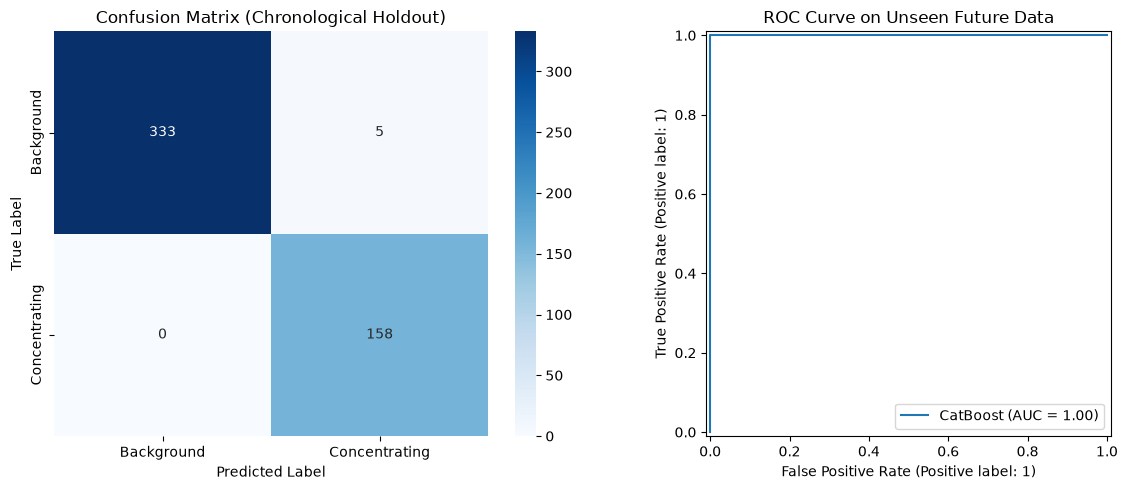

In [11]:
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay

# ==========================================
# 6. FINAL HOLDOUT VERIFICATION & ERROR ANALYSIS
# ==========================================
print("\n--- 6. Final Model Verification on Unseen Holdout Data ---")

# Strict chronological split (80% Train, 20% Test) to prevent any future-data leakage
split_idx = int(len(X) * 0.8)
X_train_final, X_test_final = X[:split_idx], X[split_idx:]
y_train_final, y_test_final = y[:split_idx], y[split_idx:]

print(f"Training on first {split_idx} samples, Testing on final {len(X) - split_idx} samples.")

# Train final verification model
verify_model = CatBoostClassifier(
    iterations=300, 
    learning_rate=0.05, 
    depth=6, 
    verbose=0, 
    random_seed=42, 
    auto_class_weights="Balanced"
)
verify_model.fit(X_train_final, y_train_final)

# Predict on unseen future data
y_pred_proba = verify_model.predict_proba(X_test_final)[:, 1]
y_pred = verify_model.predict(X_test_final)

print("\nClassification Report (Holdout Test Set):")
print(classification_report(y_test_final, y_pred, target_names=["Background (0)", "Concentrating (1)"]))

# Visualizing Performance: Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Confusion Matrix
cm = confusion_matrix(y_test_final, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=["Background", "Concentrating"], 
            yticklabels=["Background", "Concentrating"])
axes[0].set_title("Confusion Matrix (Chronological Holdout)", fontsize=12)
axes[0].set_ylabel('True Label', fontsize=10)
axes[0].set_xlabel('Predicted Label', fontsize=10)

# Plot 2: ROC Curve
RocCurveDisplay.from_predictions(
    y_test_final, 
    y_pred_proba, 
    ax=axes[1], 
    name='CatBoost'
)
axes[1].set_title("ROC Curve on Unseen Future Data", fontsize=12)
plt.tight_layout()
plt.savefig("model_verification.png", dpi=300)
plt.show()

